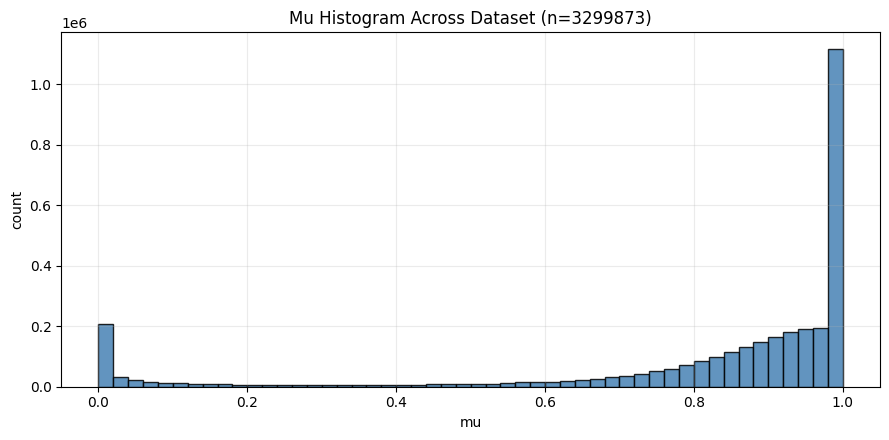

mu min=-0.0000, max=1.0000, mean=0.8037, median=0.9237, std=0.2948


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATASET_ROOT = Path("/datahome/lmertens/wayfaster_dataset")


def parse_mu(text):
    vals = np.fromstring(str(text).strip()[1:-1], sep=" ", dtype=np.float64)
    return vals[0] if vals.size > 0 else np.nan


mu_values = []
for states_path in sorted(DATASET_ROOT.rglob("states.csv")):
    try:
        states_df = pd.read_csv(states_path)
    except Exception as exc:
        print(f"Skipping {states_path.parent} (csv read failed): {exc}")
        continue
    if "traversability" not in states_df.columns:
        print(f"Skipping {states_path.parent} (missing 'traversability' column).")
        continue
    mu = states_df["traversability"].map(parse_mu).to_numpy(dtype=np.float64)
    mu_values.append(mu[np.isfinite(mu)])

if not mu_values:
    raise RuntimeError(f"No valid mu values found under {DATASET_ROOT}")

mu_values = np.concatenate(mu_values)

plt.figure(figsize=(9, 4.5))
plt.hist(mu_values, bins=50, color="steelblue", edgecolor="black", alpha=0.85)
plt.title(f"Mu Histogram Across Dataset (n={len(mu_values)})")
plt.xlabel("mu")
plt.ylabel("count")
plt.grid(alpha=0.25)
plt.tight_layout()
# Save to pdf
Path("results").mkdir(exist_ok=True)
plt.savefig("results/mu_histogram.pdf")

plt.show()


print(
    f"mu min={mu_values.min():.4f}, max={mu_values.max():.4f}, mean={mu_values.mean():.4f}, median={np.median(mu_values):.4f}, std={mu_values.std():.4f}"
)

In [2]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ---- Config ----
DATASET_ROOT = Path("/datahome/lmertens/wayfaster_dataset")
MU_THRESHOLD = 0.5  # "low" linear traversability threshold
PAD_BEFORE_S = 1  # seconds before an incident
PAD_AFTER_S = 1  # seconds after an incident
MERGE_CLOSE_S = 2.0  # merge incidents if the gap between them is <= this value
OUTPUT_VIDEO = Path("debug_high_mu_incidents.mp4")
OUTPUT_FPS = 15  # use a fixed fps for easy playback
SEPARATOR_SECONDS = 0.4  # small divider between incidents
FOOTER_H = 132  # stacked text band rendered below each frame


def parse_vec(text, expected_len=2):
    vals = np.fromstring(str(text).strip()[1:-1], sep=" ", dtype=np.float64)
    if vals.size < expected_len:
        vals = np.pad(vals, (0, expected_len - vals.size), constant_values=np.nan)
    return vals[:expected_len]


def merge_segments(segments, merge_gap=0):
    if not segments:
        return []
    segments = sorted(segments)
    merged = [list(segments[0])]
    for s, e in segments[1:]:
        if s <= merged[-1][1] + merge_gap + 1:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    return [tuple(x) for x in merged]


def compact_name(path_text, max_len=36):
    name = Path(path_text).name
    return name if len(name) <= max_len else f"...{name[-(max_len - 3) :]}"


bag_rows = []
state_files = sorted(DATASET_ROOT.rglob("states.csv"))
for states_path in tqdm(state_files, desc="Scanning bags", unit="bag"):
    bag_dir = states_path.parent
    images_path = bag_dir / "images.csv"
    if not images_path.exists():
        continue

    try:
        states_df = pd.read_csv(states_path)
        images_df = pd.read_csv(images_path)
    except Exception as exc:
        print(f"Skipping {bag_dir} (csv read failed): {exc}")
        continue

    required_states = {"timestamp", "traversability"}
    required_images = {"timestamp", "image"}
    if not required_states.issubset(states_df.columns) or not required_images.issubset(
        images_df.columns
    ):
        print(f"Skipping {bag_dir} (missing expected columns).")
        continue

    state_ts = states_df["timestamp"].to_numpy(dtype=np.float64)
    trav = np.vstack(states_df["traversability"].map(parse_vec).to_numpy())
    mu_state = trav[:, 0]
    nu_state = trav[:, 1]

    img_ts = images_df["timestamp"].to_numpy(dtype=np.float64)
    img_names = images_df["image"].astype(str).to_numpy()

    state_idx = np.searchsorted(state_ts, img_ts, side="right") - 1
    valid = (state_idx >= 0) & (state_idx < len(state_ts))
    if not np.any(valid):
        continue

    for t, img_rel, si in zip(img_ts[valid], img_names[valid], state_idx[valid]):
        bag_rows.append(
            {
                "bag": str(bag_dir),
                "timestamp": float(t),
                "image_path": str((bag_dir / img_rel).resolve()),
                "mu": float(mu_state[si]),
                "nu": float(nu_state[si]),
            }
        )

if not bag_rows:
    raise RuntimeError(f"No synchronized image/state rows found under {DATASET_ROOT}")

frames_df = (
    pd.DataFrame(bag_rows).sort_values(["bag", "timestamp"]).reset_index(drop=True)
)

# Detect high-mu incidents per bag, then expand by time padding.
incidents = []
bag_groups = list(frames_df.groupby("bag", sort=False))
for bag, grp in tqdm(
    bag_groups,
    total=len(bag_groups),
    desc="Detecting incidents",
    unit="bag",
):
    ts = grp["timestamp"].to_numpy()
    mu = grp["mu"].to_numpy()
    high = np.isfinite(mu) & (mu <= MU_THRESHOLD)
    if not np.any(high):
        continue

    starts = np.flatnonzero(high & ~np.r_[False, high[:-1]])
    ends = np.flatnonzero(high & ~np.r_[high[1:], False])

    padded_segments = []
    for s, e in zip(starts, ends):
        t0 = ts[s] - PAD_BEFORE_S
        t1 = ts[e] + PAD_AFTER_S
        ps = int(np.searchsorted(ts, t0, side="left"))
        pe = int(np.searchsorted(ts, t1, side="right") - 1)
        ps = max(0, ps)
        pe = min(len(ts) - 1, pe)
        if pe >= ps:
            padded_segments.append((ps, pe))

    if len(ts) > 1:
        dt = float(np.nanmedian(np.diff(ts)))
        dt = dt if np.isfinite(dt) and dt > 0 else 1.0 / OUTPUT_FPS
    else:
        dt = 1.0 / OUTPUT_FPS
    merge_gap_idx = max(0, int(round(MERGE_CLOSE_S / dt)))

    for ps, pe in merge_segments(padded_segments, merge_gap=merge_gap_idx):
        incident_mu_peak = float(np.nanmin(mu[ps : pe + 1]))  # NOTE
        incidents.append((bag, ps, pe, incident_mu_peak))

if not incidents:
    raise RuntimeError(f"No incidents found with mu <= {MU_THRESHOLD:.3f}")


# Find first readable frame to initialize video writer.
def first_readable_frame(paths):
    for p in paths:
        img = cv2.imread(p)
        if img is not None:
            return img
    return None


all_incident_paths = []
for bag, s, e, _ in incidents:
    grp = frames_df[frames_df["bag"] == bag].reset_index(drop=True)
    all_incident_paths.extend(grp.loc[s:e, "image_path"].tolist())

seed = first_readable_frame(all_incident_paths)
if seed is None:
    raise RuntimeError("No readable images found for detected incidents.")

h, w = seed.shape[:2]
out_h = h + FOOTER_H
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(str(OUTPUT_VIDEO), fourcc, float(OUTPUT_FPS), (w, out_h))
if not writer.isOpened():
    raise RuntimeError(f"Could not open video writer: {OUTPUT_VIDEO}")

sep_frames = max(0, int(round(SEPARATOR_SECONDS * OUTPUT_FPS)))
total_render_frames = sum(
    int(e - s + 1) for _, s, e, _ in incidents
) + sep_frames * max(0, len(incidents) - 1)
render_pbar = tqdm(total=total_render_frames, desc="Rendering video", unit="frame")

for inc_idx, (bag, s, e, peak_mu) in enumerate(incidents, start=1):
    grp = frames_df[frames_df["bag"] == bag].reset_index(drop=True)
    clip = grp.iloc[s : e + 1]
    bag_label = compact_name(bag)

    for _, row in clip.iterrows():
        frame = cv2.imread(row["image_path"])
        if frame is None:
            render_pbar.update(1)
            continue
        if frame.shape[:2] != (h, w):
            frame = cv2.resize(frame, (w, h), interpolation=cv2.INTER_AREA)

        mu = float(row["mu"])
        nu = float(row["nu"])
        text_color = (50, 70, 230) if mu <= MU_THRESHOLD else (30, 170, 30)

        canvas = np.zeros((out_h, w, 3), dtype=np.uint8)
        canvas[:h] = frame
        canvas[h:] = (18, 18, 18)
        cv2.line(canvas, (0, h), (w - 1, h), (70, 70, 70), 1)

        lines = [
            f"incident {inc_idx}/{len(incidents)}",
            f"bag {bag_label}",
            f"mu {mu:.3f}",
            f"nu {nu:.3f}",
            f"peak_mu {peak_mu:.3f} | thr {MU_THRESHOLD:.2f}",
        ]
        y_positions = [h + 22, h + 44, h + 66, h + 88, h + 110]
        colors = [
            (230, 230, 230),
            (210, 210, 210),
            text_color,
            (190, 190, 190),
            (200, 200, 200),
        ]
        scales = [0.58, 0.58, 0.58, 0.58, 0.52]
        thicknesses = [1, 1, 1, 1, 1]

        for text, y, color, scale, thickness in zip(
            lines, y_positions, colors, scales, thicknesses
        ):
            cv2.putText(
                canvas,
                text,
                (16, y),
                cv2.FONT_HERSHEY_SIMPLEX,
                scale,
                color,
                thickness,
                cv2.LINE_AA,
            )

        writer.write(canvas)
        render_pbar.update(1)

    if inc_idx < len(incidents) and sep_frames > 0:
        blank = np.zeros((out_h, w, 3), dtype=np.uint8)
        cv2.putText(
            blank,
            "--- next incident ---",
            (max(20, w // 2 - 150), out_h // 2),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            (200, 200, 200),
            2,
            cv2.LINE_AA,
        )
        for _ in range(sep_frames):
            writer.write(blank)
            render_pbar.update(1)

render_pbar.close()
writer.release()

print(f"Wrote {len(incidents)} incident clips to: {OUTPUT_VIDEO.resolve()}")
print(f"Frames analyzed: {len(frames_df)} from {frames_df['bag'].nunique()} bags")
print(
    "Tip: tune MU_THRESHOLD/PAD_BEFORE_S/PAD_AFTER_S/MERGE_CLOSE_S and re-run for faster iteration."
)

/home/lmertens/git-repos/wayfaster/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Rendering video: 100%|██████████| 18630/18630 [00:45<00:00, 405.47frame/s]

Wrote 1034 incident clips to: /home/lmertens/git-repos/wayfaster/debug_high_mu_incidents.mp4
Frames analyzed: 66104 from 65 bags
Tip: tune MU_THRESHOLD/PAD_BEFORE_S/PAD_AFTER_S/MERGE_CLOSE_S and re-run for faster iteration.
